<a href="https://colab.research.google.com/github/Alex-Iatrop/practical_data_science_first_assgnment/blob/main/assigment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



```
# Assignment 1: Personas and Context in Toxicity Annotation

**Name:** Alexander Iatropoulos  
**Seed:** 3352611  
**GitHub repository:** https://github.com/Alex-Iatrop/practical_data_science_first_assgnment.git
```

In [105]:
aimport random
import numpy as np

random.seed(3352611)
np.random.seed(3352611)

In [106]:
from pathlib import Path
from urllib.request import urlretrieve

base_url = (
    "https://raw.githubusercontent.com/"
    "Alex-Iatrop/practical_data_science_first_assgnment/main/"
)

files = [
    "items.csv",
    "items_rated.csv",
    "recovered_conversations.json",
    "baseline_with_context.json",
    "baseline_without_context.json",
    "older_left_with_context.json",
    "older_left_without_context.json",
    "older_right_with_context.json",
    "older_right_without_context.json",
    "young_left_with_context.json",
    "young_left_without_context.json",
    "young_right_with_context.json",
    "young_right_without_context.json",
]

for filename in files:
    destination = Path("/content") / filename
    if destination.exists():
        print(f"Already present: {filename}")
    else:
        urlretrieve(base_url + filename, destination)
        print(f"Downloaded: {filename}")

Already present: items.csv
Already present: items_rated.csv
Already present: recovered_conversations.json
Already present: baseline_with_context.json
Already present: baseline_without_context.json
Already present: older_left_with_context.json
Already present: older_left_without_context.json
Already present: older_right_with_context.json
Already present: older_right_without_context.json
Already present: young_left_with_context.json
Already present: young_left_without_context.json
Already present: young_right_with_context.json
Already present: young_right_without_context.json


In [107]:
import pandas as pd

items = pd.read_csv("/content/items.csv")
rated = pd.read_csv("/content/items_rated.csv")

# Display all rows and the complete text in each cell
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

print("Original comments:")
display(items)

print("My ratings:")
display(rated)

Original comments:


,id,text,rating,label,evidence
0,1,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",NaN,NaN,NaN
1,2,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,NaN,NaN,NaN
2,3,"... stupid people are a fact of life, just look at who they elected President.",NaN,NaN,NaN
3,4,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",NaN,NaN,NaN
4,5,"An ""atheist""?, now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",NaN,NaN,NaN
5,6,"So much for civility, Roy's vitriol is the same boorish nut-job suggesting killing hunters.",NaN,NaN,NaN
6,7,"Thanks Bob, but according to Ted Baker I was writing barracuda stories on my government work station all day and just missed the call, so feel free to go with that version if it helps.",NaN,NaN,NaN
7,8,Julian should receive the Gold Star award from Russian intelligence for his role in attacking democracy and the Silver Rapist award from Ecuador. I hope he rots.,NaN,NaN,NaN
8,9,"Where's the outrage, klastri, homer, keaukaha, boots, allie, cellodad, all registered sex offenders? That's how the Democrats roll. Hypocrites, liars, Bigots, racist, sexists, LOL",NaN,NaN,NaN
9,10,It williams be interesting if this starts a full audit into all their expense claims by an independent auditor! I suspect there are quite a few pigs at the trough!,NaN,NaN,NaN


My ratings:


,id,text,rating,label,evidence
0,1,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",1,civil,not needed
1,2,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,2,civil,not needed
2,3,"... stupid people are a fact of life, just look at who they elected President.",3,toxic,stupid || look at who
3,4,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",2,civil,not needed
4,5,"An ""atheist""?, now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",4,toxic,it's even more stupid || IMUA!!!
5,6,"So much for civility, Roy's vitriol is the same boorish nut-job suggesting killing hunters.",2,civil,not needed
6,7,"Thanks Bob, but according to Ted Baker I was writing barracuda stories on my government work station all day and just missed the call, so feel free to go with that version if it helps.",3,toxic,but according to Ted Baker I was writing barracuda stories on my government w
7,8,Julian should receive the Gold Star award from Russian intelligence for his role in attacking democracy and the Silver Rapist award from Ecuador. I hope he rots.,3,toxic,I hope he rots.
8,9,"Where's the outrage, klastri, homer, keaukaha, boots, allie, cellodad, all registered sex offenders? That's how the Democrats roll. Hypocrites, liars, Bigots, racist, sexists, LOL",3,toxic,"Hypocrites, liars, Bigots, racist, sexists, LOL"
9,10,It williams be interesting if this starts a full audit into all their expense claims by an independent auditor! I suspect there are quite a few pigs at the trough!,4,toxic,quite a few pigs at the trough!


In [108]:
items

,id,text,rating,label,evidence
0,1,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",NaN,NaN,NaN
1,2,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,NaN,NaN,NaN
2,3,"... stupid people are a fact of life, just look at who they elected President.",NaN,NaN,NaN
3,4,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",NaN,NaN,NaN
4,5,"An ""atheist""?, now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",NaN,NaN,NaN
5,6,"So much for civility, Roy's vitriol is the same boorish nut-job suggesting killing hunters.",NaN,NaN,NaN
6,7,"Thanks Bob, but according to Ted Baker I was writing barracuda stories on my government work station all day and just missed the call, so feel free to go with that version if it helps.",NaN,NaN,NaN
7,8,Julian should receive the Gold Star award from Russian intelligence for his role in attacking democracy and the Silver Rapist award from Ecuador. I hope he rots.,NaN,NaN,NaN
8,9,"Where's the outrage, klastri, homer, keaukaha, boots, allie, cellodad, all registered sex offenders? That's how the Democrats roll. Hypocrites, liars, Bigots, racist, sexists, LOL",NaN,NaN,NaN
9,10,It williams be interesting if this starts a full audit into all their expense claims by an independent auditor! I suspect there are quite a few pigs at the trough!,NaN,NaN,NaN


In [109]:
rated

,id,text,rating,label,evidence
0,1,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",1,civil,not needed
1,2,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,2,civil,not needed
2,3,"... stupid people are a fact of life, just look at who they elected President.",3,toxic,stupid || look at who
3,4,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",2,civil,not needed
4,5,"An ""atheist""?, now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",4,toxic,it's even more stupid || IMUA!!!
5,6,"So much for civility, Roy's vitriol is the same boorish nut-job suggesting killing hunters.",2,civil,not needed
6,7,"Thanks Bob, but according to Ted Baker I was writing barracuda stories on my government work station all day and just missed the call, so feel free to go with that version if it helps.",3,toxic,but according to Ted Baker I was writing barracuda stories on my government w
7,8,Julian should receive the Gold Star award from Russian intelligence for his role in attacking democracy and the Silver Rapist award from Ecuador. I hope he rots.,3,toxic,I hope he rots.
8,9,"Where's the outrage, klastri, homer, keaukaha, boots, allie, cellodad, all registered sex offenders? That's how the Democrats roll. Hypocrites, liars, Bigots, racist, sexists, LOL",3,toxic,"Hypocrites, liars, Bigots, racist, sexists, LOL"
9,10,It williams be interesting if this starts a full audit into all their expense claims by an independent auditor! I suspect there are quite a few pigs at the trough!,4,toxic,quite a few pigs at the trough!


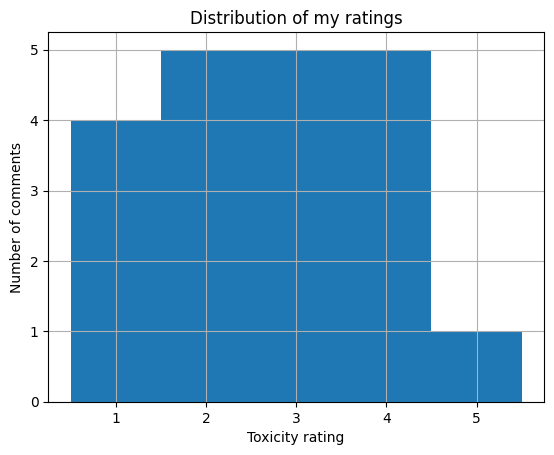

In [110]:
import matplotlib.pyplot as plt

rated["rating"].hist(bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5])
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Toxicity rating")
plt.ylabel("Number of comments")
plt.title("Distribution of my ratings")
plt.show()

For the generation of this graph I have chosen the above historgram which gathers the data of my ratings and puts them into bins of size 1. I want the centers of each rating to be at the center of the bin. Thus I have chosen the bins to start from 0.5-1.5 etc. The graph shows how I have rated the comments randomly chosen by the the items.csv. Most ratings are between 2 and 4 while I rarely selected 5. The distribution seems to be slightly right skewed, but more data is needed to draw any final conclusions.

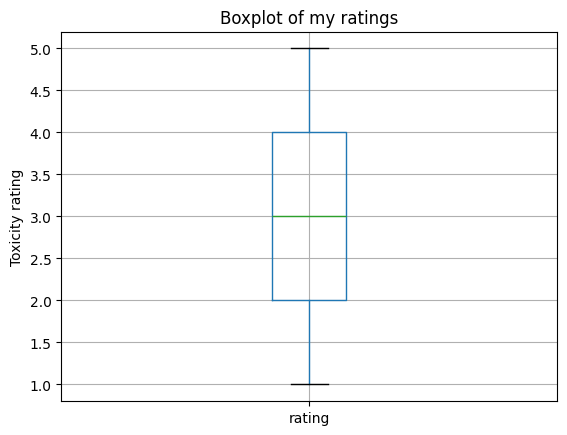

In [111]:
rated.boxplot(column="rating")
plt.ylabel("Toxicity rating")
plt.title("Boxplot of my ratings")
plt.show()

The box plot provides a summary of my ratings. We can observe that the IQR is between 2-4 ratings, that is, the 50% of the data are gathered between the two values. The slight skweness is not clearly visible here, and we cannot draw any conclusions due to the size of the sample.

In [112]:
import json

# Load the 20 previously generated conversations
with open("/content/recovered_conversations.json", encoding="utf-8") as file:
    saved_conversations = json.load(file)

# Convert JSON keys back to integer item IDs
conversations = {
    int(item_id): entries
    for item_id, entries in saved_conversations.items()
}

print("Conversations loaded:", len(conversations))

Conversations loaded: 20


In [113]:
# Display all saved conversations
for item_id, entries in conversations.items():
    print(f"\n--- Conversation {item_id} ---")

    for entry in entries:
        print(f'{entry["name"]}: {entry["text"]}')


--- Conversation 1 ---
OriginalPoster: Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.
Maria_K: It's true that their flight path matters, but focusing solely on this detail misses the bigger picture. We need more context to fully understand the situation.
Tom_77: Flying in international airspace is indeed crucial info, but diving too deep into one aspect can overshadow other important details. Let's look at it all together!
Maria_K: That's a valid point. While the flight path is important, we should also consider other factors that provide a comprehensive view of the situation.
Sofia: I see your point, but I think it’s fair to highlight the key aspects without losing sight of the broader context. The flight path is certainly relevant, but so are other critical pieces of information.

--- Conversation 2 ---
OriginalPoster: I'm white so no pudding for you Mr.Trum

In [114]:
import json
import pandas as pd

annotator_personas = {
    "young_left": {"age": "under 30", "politics": "left"},
    "young_right": {"age": "under 30", "politics": "right"},
    "older_left": {"age": "over 50", "politics": "left"},
    "older_right": {"age": "over 50", "politics": "right"},
    "baseline": {}
}

# Load the saved annotations for each persona and condition
all_results = []

for persona_name in annotator_personas:
    for condition in ["without_context", "with_context"]:
        filename = f"/content/{persona_name}_{condition}.json"

        with open(filename, encoding="utf-8") as file:
            all_results.extend(json.load(file))

results_df = pd.DataFrame(all_results)

print("Total annotations:", len(results_df))
print(
    "Duplicate combinations:",
    results_df.duplicated(["id", "annotator", "condition"]).sum()
)

Total annotations: 200
Duplicate combinations: 0


In [115]:
# Split each answer into its rating and evidence
parts = results_df["answer"].str.split("|", n=1, expand=True)

results_df["rating"] = pd.to_numeric(
    parts[0].str.strip(), errors="coerce"
)

results_df["evidence"] = (
    parts[1].str.strip() if parts.shape[1] > 1 else None
)

# Check the rating and whether the evidence appears in the comment
def check_answer(row):
    rating = row["rating"]
    evidence = row["evidence"]
    text = row["text"]

    if pd.isna(rating) or rating not in [1, 2, 3, 4, 5]:
        return "invalid rating"

    if rating >= 3:
        if pd.isna(evidence) or not evidence.strip():
            return "missing evidence"

        cleaned = evidence.strip().strip("\"'“”‘’").strip()

        if not cleaned or cleaned not in text:
            return "evidence not found in text"

    return "valid"

results_df["validation"] = results_df.apply(check_answer, axis=1)

# Convert scores into civil/toxic labels
def get_label(rating):
    if pd.isna(rating) or rating not in [1, 2, 3, 4, 5]:
        return None
    return "civil" if rating <= 2 else "toxic"

results_df["label"] = results_df["rating"].apply(get_label)

valid_results = results_df[results_df["validation"] == "valid"].copy()

print("Validation results:")
print(results_df["validation"].value_counts())

Validation results:
validation
valid                         160
evidence not found in text     40
Name: count, dtype: int64


In [116]:
# Count validation outcomes for each annotator and condition
validation_table = (
    results_df
    .groupby(["annotator", "condition", "validation"])
    .size()
    .unstack(fill_value=0)
)

display(validation_table)

validation                   evidence not found in text  valid
annotator   condition                                         
baseline    with_context                              4     16
            without_context                           5     15
older_left  with_context                              4     16
            without_context                           3     17
older_right with_context                              3     17
            without_context                           4     16
young_left  with_context                              4     16
            without_context                           4     16
young_right with_context                              4     16
            without_context                           5     15

In [117]:
rated["rating"].value_counts().sort_index()

,count
rating,
1,4
2,5
3,5
4,5
5,1


In [118]:
print("Number of items:", len(items))
print("Number of ratings:", len(rated))

Number of items: 20
Number of ratings: 20


In [119]:
!pip install -q syndisco

In [120]:
import json                 # to save the conversations
import random               # to choose random participants
import re                   # to find the rating in the model's answer

import pandas as pd         # for the tables
import torch                # the library that runs the model
import syndisco             # the library of this lab

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: none (Runtime > Change runtime type > T4 GPU)


In [121]:
texts = dict(zip(items["id"], items["text"]))

In [122]:
def load_model():
    """Load the model if the generation functions need to be run again."""
    return syndisco.TransformersModel(
        model_path="unsloth/Qwen2.5-3B-Instruct-bnb-4bit",
        name="qwen",
        max_out_tokens=80,
        generation_kwargs={"repetition_penalty": 1.1}
    )

In [123]:
# a small pool of made-up people: each is just a dictionary of attributes
PERSONAS = [
    {"username": "Maria_K", "age": 38, "job": "nurse", "personality": ["patient", "direct"]},
    {"username": "Giannis", "age": 21, "job": "game developer", "personality": ["sarcastic", "curious"]},
    {"username": "Kimya", "age": 67, "job": "retired teacher", "personality": ["strict", "grumpy"]},
    {"username": "Tom_77", "age": 45, "job": "truck driver", "personality": ["blunt", "funny"]},
    {"username": "Sofia", "age": 29, "job": "journalist", "personality": ["skeptical", "polite"]},
]

# the same context and instructions for every participant
CONTEXT = (
    "You are a commenter in a discussion thread on a news website. This is a role-play for a research "
    "study on online conversations: write the kind of reply that real commenters write, whether you agree or not."
)
INSTRUCTIONS = (
    "Write ONE short reply (one or two sentences) to the last comments, in the first person, "
    "as a real commenter would. React to what was said. Do not explain, do not refuse, "
    "do not mention that you are an AI, and never answer with an apology or a refusal."
)

In [124]:
import random
def generate_conversations():
  rng = random.Random(0)
  conversations = {}

  for item_id, text in texts.items():
      # The initial comment is known to everyone
      context_for_item = CONTEXT + "\nOriginal comment: " + text

      # we chose 3 pariticipants for this disucsioon
      users = []
      for persona in rng.sample(PERSONAS, 3):
          user = syndisco.Actor(
              model=model,
              persona=persona,
              context=context_for_item,
              instructions=INSTRUCTIONS,
              name=persona["username"]
          )
          users.append(user)

      discussion = syndisco.Discussion(
          next_turn_manager=syndisco.RandomTurnManager(users),
          users=users,
          conv_len=4,
          seed_opinions=[text],
          seed_opinion_usernames=["OriginalPoster"]
      )

      discussion.begin(verbose=False)
      conversations[item_id] = discussion.get_logs()

      print(f"Conversation {item_id} completed")

In [125]:
for item_id, logs in conversations.items():
    print(f"\n--- Conversation {item_id} ---")

    for entry in logs:
        print(f'{entry["name"]}: {entry["text"]}')


--- Conversation 1 ---
OriginalPoster: Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.
Maria_K: It's true that their flight path matters, but focusing solely on this detail misses the bigger picture. We need more context to fully understand the situation.
Tom_77: Flying in international airspace is indeed crucial info, but diving too deep into one aspect can overshadow other important details. Let's look at it all together!
Maria_K: That's a valid point. While the flight path is important, we should also consider other factors that provide a comprehensive view of the situation.
Sofia: I see your point, but I think it’s fair to highlight the key aspects without losing sight of the broader context. The flight path is certainly relevant, but so are other critical pieces of information.

--- Conversation 2 ---
OriginalPoster: I'm white so no pudding for you Mr.Trum

In [126]:
import json

with open("generated.jsonl", "w", encoding="utf-8") as f:
    for item_id, logs in conversations.items():
        entry = {
            "id": item_id,
            "conversation": [
                {"name": e["name"], "text": e["text"]}
                for e in logs
            ]
        }
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")

print("Conversations saved.")

Conversations saved.


In [127]:
annotator_personas = {
    "young_left": {
        "age": "under 30",
        "politics": "left"
    },
    "young_right": {
        "age": "under 30",
        "politics": "right"
    },
    "older_left": {
        "age": "over 50",
        "politics": "left"
    },
    "older_right": {
        "age": "over 50",
        "politics": "right"
    },
    "baseline": {}
}

annotator_personas

{'young_left': {'age': 'under 30', 'politics': 'left'},
 'young_right': {'age': 'under 30', 'politics': 'right'},
 'older_left': {'age': 'over 50', 'politics': 'left'},
 'older_right': {'age': 'over 50', 'politics': 'right'},
 'baseline': {}}

In [128]:
# same intriction are given to the personas too
RATING_INSTRUCTIONS = (
    "Rate how toxic the comment is, from 1 (fully civil) "
    "to 5 (very toxic). "
    "For a rating of 3, 4 or 5, copy the exact words from the comment "
    "that justify your rating. For a rating of 1 or 2, write not needed. "
    "Reply using only this format: <number> | <evidence>."
)

In [129]:
import json
def generate_annotations():
  results = []

  for persona_name, persona in annotator_personas.items():

      for condition in ["without_context", "with_context"]:

          for item_id, text in texts.items():

              # Στη δεύτερη συνθήκη ο annotator διαβάζει
              # και τη συζήτηση για το συγκεκριμένο σχόλιο.
              if condition == "with_context":
                  context = "\n".join(
                      f'{entry["name"]}: {entry["text"]}'
                      for entry in conversations[item_id]
                  )
              else:
                  context = ""

              annotator = syndisco.Actor(
                  model=model,
                  persona=persona,
                  context=context,
                  instructions=RATING_INSTRUCTIONS,
                  is_annotator=True,
                  name=persona_name
              )

              logs = syndisco.Logs()
              logs.append("comment", text)

              annotation = syndisco.Annotation(
                  annotator=annotator,
                  discussion_logs=logs
              )

              annotation.begin(verbose=False)
              output = annotation.get_logs()[0]

              result = {
                  "id": int(item_id),
                  "text": text,
                  "annotator": persona_name,
                  "condition": condition,
                  "answer": output["text"],
                  "prompt": output["prompt"]
              }

              results.append(result)

              # Αποθηκεύουμε κάθε απάντηση μόλις παραχθεί
              with open("annotation_results.jsonl", "a", encoding="utf-8") as f:
                  f.write(json.dumps(result, ensure_ascii=False) + "\n")

              print(f"{persona_name} | {condition} | item {item_id}: done")

  print(f"Completed: {len(results)} annotations")

In [130]:
# split the answer on the first symbol |
parts = results_df["answer"].str.split("|", n=1, expand=True)

# we create 2 new columns
results_df["rating"] = pd.to_numeric(parts[0].str.strip(), errors="coerce")
results_df["evidence"] = parts[1].str.strip() if parts.shape[1] > 1 else None

results_df[["id", "annotator", "condition", "answer", "rating", "evidence"]].head()

,id,annotator,condition,answer,rating,evidence
0,1,young_left,without_context,"3 | Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",3,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information."
1,2,young_left,without_context,1 | not_needed,1,not_needed
2,3,young_left,without_context,3 | just look at who they elected President.,3,just look at who they elected President.
3,4,young_left,without_context,"3 | No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really."
4,5,young_left,without_context,"3 | , now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",3,", now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!"


In [131]:
invalid = results_df[results_df["validation"] != "valid"]

for _, row in invalid.head(5).iterrows():
    print("ID:", row["id"])
    print("Annotator:", row["annotator"])
    print("Condition:", row["condition"])
    print("Original text:", row["text"])
    print("Model evidence:", row["evidence"])
    print("-" * 60)

ID: 7
Annotator: young_left
Condition: without_context
Original text: Thanks Bob, but according to Ted Baker I was writing barracuda stories on my government work station all day and just missed the call, so feel free to go with that version if it helps.
Model evidence: According to Ted Baker I was writing barracuda stories on my government work station all day and just missed the call, so feel free to go with that version if it helps.
------------------------------------------------------------
ID: 11
Annotator: young_left
Condition: without_context
Original text: So is Eric senior still eligible for “Father of the Year” if his son’s dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he’s a deviant sexual predator. Way to go Eric Sr.! Hang in there!
Model evidence: So is Eric senior still eligible for \u201cFather of the year\u201d if his son\u2019s dead body was found bloated full of

In [132]:
import json
import re
from pathlib import Path

# I downloaded the assignment file because I was blocked by the paywall of google colab. I am looking into the ocnversations with this small script
notebooks = list(Path("/content").glob("*.ipynb"))
print("Notebooks found:", [p.name for p in notebooks])

Notebooks found: []


In [133]:
!pip install -q syndisco

In [134]:
import syndisco
import torch

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

GPU: No GPU


In [135]:
texts = {}

for item_id, logs in conversations.items():
    texts[item_id] = logs[0]["text"]

print("Texts:", len(texts))
print("Conversations:", len(conversations))

Texts: 20
Conversations: 20


In [136]:
annotator_personas = {
    "young_left": {"age": "under 30", "politics": "left"},
    "young_right": {"age": "under 30", "politics": "right"},
    "older_left": {"age": "over 50", "politics": "left"},
    "older_right": {"age": "over 50", "politics": "right"},
    "baseline": {}
}

print("Annotators:", len(annotator_personas))

Annotators: 5


In [137]:
RATING_INSTRUCTIONS = (
    "Rate how toxic the comment is, from 1 (fully civil) "
    "to 5 (very toxic). "
    "For a rating of 3, 4 or 5, copy the exact words from the comment "
    "that justify your rating. For a rating of 1 or 2, write not needed. "
    "Reply using only this format: <number> | <evidence>."
)

print("Instructions ready.")

Instructions ready.


In [138]:
import json
def generate_young_left_without_context():
  persona_name = "young_left"
  condition = "without_context"
  batch_results = []

  for item_id, text in texts.items():
      annotator = syndisco.Actor(
          model=model,
          persona=annotator_personas[persona_name],
          context="",
          instructions=RATING_INSTRUCTIONS,
          is_annotator=True,
          name=persona_name
      )

      logs = syndisco.Logs()
      logs.append("comment", text)

      annotation = syndisco.Annotation(
          annotator=annotator,
          discussion_logs=logs
      )
      annotation.begin(verbose=False)

      output = annotation.get_logs()[0]

      batch_results.append({
          "id": int(item_id),
          "text": text,
          "annotator": persona_name,
          "condition": condition,
          "answer": output["text"],
          "prompt": output["prompt"]
      })

      print(f"Item {item_id}: done")

  # save the group in colab for future download
  filename = f"{persona_name}_{condition}.json"

  with open(filename, "w", encoding="utf-8") as f:
      json.dump(batch_results, f, ensure_ascii=False, indent=2)

  print(f"Saved {len(batch_results)} answers to {filename}")

In [139]:
def generate_young_left_with_context():
  persona_name = "young_left"
  condition = "with_context"
  batch_results = []

  for item_id, text in texts.items():
      #conversation to text
      context = "\n".join(
          f'{entry["name"]}: {entry["text"]}'
          for entry in conversations[item_id]
      )

      annotator = syndisco.Actor(
          model=model,
          persona=annotator_personas[persona_name],
          context=context,
          instructions=RATING_INSTRUCTIONS,
          is_annotator=True,
          name=persona_name
      )

      #annotate only the first comment
      logs = syndisco.Logs()
      logs.append("comment", text)

      annotation = syndisco.Annotation(
          annotator=annotator,
          discussion_logs=logs
      )
      annotation.begin(verbose=False)

      output = annotation.get_logs()[0]

      batch_results.append({
          "id": int(item_id),
          "text": text,
          "annotator": persona_name,
          "condition": condition,
          "answer": output["text"],
          "prompt": output["prompt"]
      })

      print(f"Item {item_id}: done")

  filename = f"{persona_name}_{condition}.json"

  with open(filename, "w", encoding="utf-8") as f:
      json.dump(batch_results, f, ensure_ascii=False, indent=2)

  print(f"Saved {len(batch_results)} answers to {filename}")

In [140]:
import json
def generate_remaining_annotations():
  # the rest of the personas. no need to do it one by one
  remaining = ["young_right", "older_left", "older_right", "baseline"]

  for persona_name in remaining:

      for condition in ["without_context", "with_context"]:
          batch_results = []

          for item_id, text in texts.items():

              if condition == "with_context":
                  context = "\n".join(
                      f'{entry["name"]}: {entry["text"]}'
                      for entry in conversations[item_id]
                  )
              else:
                  context = ""

              annotator = syndisco.Actor(
                  model=model,
                  persona=annotator_personas[persona_name],
                  context=context,
                  instructions=RATING_INSTRUCTIONS,
                  is_annotator=True,
                  name=persona_name
              )

              logs = syndisco.Logs()
              logs.append("comment", text)

              annotation = syndisco.Annotation(
                  annotator=annotator,
                  discussion_logs=logs
              )

              annotation.begin(verbose=False)
              output = annotation.get_logs()[0]

              batch_results.append({
                  "id": int(item_id),
                  "text": text,
                  "annotator": persona_name,
                  "condition": condition,
                  "answer": output["text"],
                  "prompt": output["prompt"]
              })

              print(f"{persona_name} | {condition} | item {item_id}: done")

          filename = f"{persona_name}_{condition}.json"

          with open(filename, "w", encoding="utf-8") as f:
              json.dump(batch_results, f, ensure_ascii=False, indent=2)

          print(f"\n✅ Saved {len(batch_results)} answers: {filename}\n")

  print("All remaining groups completed.")

In [141]:
from pathlib import Path

for persona_name in annotator_personas:
    for condition in ["without_context", "with_context"]:
        filename = f"{persona_name}_{condition}.json"
        path = Path("/content") / filename

        if path.exists():
            with open(path, encoding="utf-8") as f:
                batch = json.load(f)
            print(f"{filename}: {len(batch)} answers")
        else:
            print(f"{filename}: NOT FOUND in Colab")

young_left_without_context.json: 20 answers
young_left_with_context.json: 20 answers
young_right_without_context.json: 20 answers
young_right_with_context.json: 20 answers
older_left_without_context.json: 20 answers
older_left_with_context.json: 20 answers
older_right_without_context.json: 20 answers
older_right_with_context.json: 20 answers
baseline_without_context.json: 20 answers
baseline_with_context.json: 20 answers


In [142]:
def get_label(rating):
    if pd.isna(rating) or rating not in [1, 2, 3, 4, 5]:
        return None
    elif rating <= 2:
        return "civil"
    else:
        return "toxic"

results_df["label"] = results_df["rating"].apply(get_label)

# keep separte matrix for comparisons
valid_results = results_df[results_df["validation"] == "valid"].copy()

print("Valid answers for comparisons:", len(valid_results))
display(
    valid_results[
        ["id", "annotator", "condition", "rating", "label", "evidence"]
    ].head()
)

Valid answers for comparisons: 160


,id,annotator,condition,rating,label,evidence
0,1,young_left,without_context,3,toxic,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information."
1,2,young_left,without_context,1,civil,not_needed
2,3,young_left,without_context,3,toxic,just look at who they elected President.
3,4,young_left,without_context,3,toxic,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really."
4,5,young_left,without_context,3,toxic,", now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!"


Only 160 out of 200 answers have passed. The code checked the answers/evidence for the 40 invalid ones and it couldn't find the macthing text in the original comment.

In [143]:
print("rated" in globals())

True


In [144]:
rated = pd.read_csv("/content/items_rated.csv")

print("My ratings:", len(rated))
display(rated.head())

My ratings: 20


,id,text,rating,label,evidence
0,1,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",1,civil,not needed
1,2,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,2,civil,not needed
2,3,"... stupid people are a fact of life, just look at who they elected President.",3,toxic,stupid || look at who
3,4,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",2,civil,not needed
4,5,"An ""atheist""?, now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",4,toxic,it's even more stupid || IMUA!!!


In [145]:
import pandas as pd

rated = pd.read_csv("/content/items_rated.csv")

print("Number of comments:", len(rated))
display(rated.head())

Number of comments: 20


,id,text,rating,label,evidence
0,1,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",1,civil,not needed
1,2,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,2,civil,not needed
2,3,"... stupid people are a fact of life, just look at who they elected President.",3,toxic,stupid || look at who
3,4,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",2,civil,not needed
4,5,"An ""atheist""?, now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",4,toxic,it's even more stupid || IMUA!!!


In [146]:
# Compare the comments using their IDs
check = results_df.merge(
    rated[["id", "text"]],
    on="id",
    suffixes=("_model", "_human")
)

check["same_text"] = (
    check["text_model"].str.strip() == check["text_human"].str.strip()
)

print("Total responses compared:", len(check))
print("Responses with matching text:", check["same_text"].sum())
print("Responses with different text:", (~check["same_text"]).sum())

Total responses compared: 200
Responses with matching text: 200
Responses with different text: 0


In [147]:
# Add the human ratings to the valid model responses
comparison = valid_results.merge(
    rated[["id", "rating", "label"]],
    on="id",
    suffixes=("_model", "_human"),
    validate="many_to_one"
)

# Check agreement for each response
comparison["rating_agreement"] = (
    comparison["rating_model"] == comparison["rating_human"]
)

comparison["label_agreement"] = (
    comparison["label_model"] == comparison["label_human"]
)

# Summarize agreement by annotator and condition
human_comparison = comparison.groupby(
    ["annotator", "condition"]
).agg(
    comments_compared=("id", "size"),
    exact_rating_agreement=("rating_agreement", "mean"),
    label_agreement=("label_agreement", "mean")
)

human_comparison[["exact_rating_agreement", "label_agreement"]] *= 100

display(human_comparison.round(1))

comments_compared  exact_rating_agreement  \
annotator   condition                                                    
baseline    with_context                    16                     6.2   
            without_context                 15                    13.3   
older_left  with_context                    16                     0.0   
            without_context                 17                    17.6   
older_right with_context                    17                     0.0   
            without_context                 16                    18.8   
young_left  with_context                    16                     6.2   
            without_context                 16                    12.5   
young_right with_context                    16                     6.2   
            without_context                 15                    20.0   

                             label_agreement  
annotator   condition                         
baseline    with_context                68.8  
            without_context             46.7  
older_left  with_context                68.8  
            without_context             58.8  
older_right with_context                64.7  
            without_context             56.2  
young_left  with_context                68.8  
            without_context             56.2  
young_right with_context                68.8  
            without_context             53.3

In [148]:
# Put the two conditions side by side for each persona and comment
paired_context = valid_results.pivot(
    index=["annotator", "id"],
    columns="condition",
    values=["rating", "label"]
).dropna()

# Create a simple table with one row per matched pair
paired_comparison = pd.DataFrame(index=paired_context.index)

paired_comparison["rating_agreement"] = (
    paired_context[("rating", "with_context")]
    == paired_context[("rating", "without_context")]
)

paired_comparison["label_agreement"] = (
    paired_context[("label", "with_context")]
    == paired_context[("label", "without_context")]
)

# Summarize agreement for each persona
context_comparison = paired_comparison.groupby("annotator").agg(
    comments_compared=("rating_agreement", "size"),
    exact_rating_agreement=("rating_agreement", "mean"),
    label_agreement=("label_agreement", "mean")
)

context_comparison[["exact_rating_agreement", "label_agreement"]] *= 100

display(context_comparison.round(1))

,comments_compared,exact_rating_agreement,label_agreement
annotator,,,
baseline,13,38.5,61.5
older_left,15,46.7,66.7
older_right,15,40.0,66.7
young_left,15,40.0,53.3
young_right,13,30.8,46.2


In [149]:
from itertools import combinations

persona_pairs = []

for condition in valid_results["condition"].unique():
    condition_data = valid_results[
        valid_results["condition"] == condition
    ]

    # Compare every pair of personas on the same comments
    for persona_a, persona_b in combinations(
        sorted(condition_data["annotator"].unique()), 2
    ):
        a = condition_data[condition_data["annotator"] == persona_a]
        b = condition_data[condition_data["annotator"] == persona_b]

        paired = a.merge(
            b,
            on="id",
            suffixes=("_a", "_b"),
            validate="one_to_one"
        )

        persona_pairs.append({
            "condition": condition,
            "persona_a": persona_a,
            "persona_b": persona_b,
            "comments_compared": len(paired),
            "exact_rating_agreement": (
                paired["rating_a"] == paired["rating_b"]
            ).mean() * 100,
            "label_agreement": (
                paired["label_a"] == paired["label_b"]
            ).mean() * 100
        })

persona_comparison = pd.DataFrame(persona_pairs)

display(persona_comparison.round(1))

,condition,persona_a,persona_b,comments_compared,exact_rating_agreement,label_agreement
0,without_context,baseline,older_left,15,86.7,93.3
1,without_context,baseline,older_right,13,92.3,92.3
2,without_context,baseline,young_left,15,86.7,93.3
3,without_context,baseline,young_right,13,92.3,92.3
4,without_context,older_left,older_right,15,100.0,100.0
5,without_context,older_left,young_left,16,100.0,100.0
6,without_context,older_left,young_right,15,100.0,100.0
7,without_context,older_right,young_left,14,100.0,100.0
8,without_context,older_right,young_right,15,100.0,100.0
9,without_context,young_left,young_right,14,100.0,100.0


In the table above, we compare the agreement between the annotators. The first column shows the condition, with or without context. The second column, persona_a, is the type of annotator that we compare with the annotator in the persona_b column. Next is the number of comments compared, followed by the exact rating agreement, which describes the percentage of comments with the same rating, and lastly the label agreement, which is the agreement on the category.The agreement between the model annotators is generally high for both the exact rating and the label. The exact rating agreement ranges from 86.7% to 100%. With context, older right and young left agree at 87.5%, which is the same as older right and young right. The lowest agreement, 86.7%, occurs between older left and young left, among other pairs. These results suggest that age may play a role in the model’s ratings. Another observation is that older left and older right reach an agreement of 100%. The age result should be treated cautiously: each pair was compared on a small number of valid comments, and other pairs also had 86.7% agreement.

In [150]:
# Exclude comparisons involving the baseline
persona_only = persona_comparison[
    (persona_comparison["persona_a"] != "baseline")
    & (persona_comparison["persona_b"] != "baseline")
]

# Calculate the average across persona pairs for each condition
average_persona_agreement = persona_only.groupby("condition").agg(
    average_exact_rating_agreement=("exact_rating_agreement", "mean"),
    average_label_agreement=("label_agreement", "mean")
)

display(average_persona_agreement.round(1))

,average_exact_rating_agreement,average_label_agreement
condition,,
with_context,91.4,91.4
without_context,100.0,100.0


In [151]:
# Average agreement across all pairs, including the baseline
average_all_agreement = persona_comparison.groupby("condition").agg(
    average_exact_rating_agreement=("exact_rating_agreement", "mean"),
    average_label_agreement=("label_agreement", "mean")
)

display(average_all_agreement.round(1))

,average_exact_rating_agreement,average_label_agreement
condition,,
with_context,92.2,93.5
without_context,95.8,97.1


In [152]:
# Rank annotators by agreement with human labels
human_ranking = human_comparison.reset_index().sort_values(
    ["condition", "label_agreement"],
    ascending=[True, False]
)

display(human_ranking.round(1))

,annotator,condition,comments_compared,exact_rating_agreement,label_agreement
0,baseline,with_context,16,6.2,68.8
2,older_left,with_context,16,0.0,68.8
6,young_left,with_context,16,6.2,68.8
8,young_right,with_context,16,6.2,68.8
4,older_right,with_context,17,0.0,64.7
3,older_left,without_context,17,17.6,58.8
5,older_right,without_context,16,18.8,56.2
7,young_left,without_context,16,12.5,56.2
9,young_right,without_context,15,20.0,53.3
1,baseline,without_context,15,13.3,46.7


This table compares my ratings with those generated by the model for each annotator and condition. The annotator column identifies the persona used, while condition indicates whether the annotator received the conversation as context. Comments compared shows the number of comments included in each comparison.
Exact rating agreement is the percentage of compared comments for which the annotator assigned the same numerical rating as I did. Label agreement is the percentage for which we agreed on the broader category: ratings of 1–2 are classified as civil, while ratings of 3–5 are classified as toxic.
Exact rating agreement was low across all conditions. The highest values occurred without context: 20.0% for young right, 18.8% for older right, and 17.6% for older left. Label agreement ranged from 46.7% to 68.8%, meaning that the annotators and I disagreed on the category for approximately 31%–53% of the compared comments. These results should be interpreted cautiously because each comparison included only 15–17 valid annotations, and the comments included may differ between conditions.

In [153]:
# Pairs differing in age only
age_pairs = [
    ("older_left", "young_left"),
    ("older_right", "young_right")
]

# Pairs differing in politics only
politics_pairs = [
    ("older_left", "older_right"),
    ("young_left", "young_right")
]

dimension_comparison = persona_comparison.copy()

def identify_dimension(row):
    pair = (row["persona_a"], row["persona_b"])

    if pair in age_pairs:
        return "age"
    if pair in politics_pairs:
        return "politics"
    return "other"

dimension_comparison["dimension"] = dimension_comparison.apply(
    identify_dimension, axis=1
)

# Average agreement across the relevant pairs
dimension_summary = (
    dimension_comparison[
        dimension_comparison["dimension"].isin(["age", "politics"])
    ]
    .groupby(["condition", "dimension"])
    .agg(
        average_rating_agreement=("exact_rating_agreement", "mean"),
        average_label_agreement=("label_agreement", "mean")
    )
)

display(dimension_summary.round(1))

average_rating_agreement  average_label_agreement
condition       dimension                                                   
with_context    age                            87.1                     87.1
                politics                      100.0                    100.0
without_context age                           100.0                    100.0
                politics                      100.0                    100.0

In [154]:
# Compare ratings for the same persona and comment in both conditions
context_changes = paired_context["rating"].copy()

context_changes["difference"] = (
    context_changes["with_context"]
    - context_changes["without_context"]
)

# Count increases, decreases, and unchanged ratings
context_direction = context_changes.groupby("annotator")["difference"].agg(
    comments_compared="size",
    increased=lambda x: (x > 0).sum(),
    decreased=lambda x: (x < 0).sum(),
    unchanged=lambda x: (x == 0).sum(),
    average_change="mean"
)

display(context_direction.round(2))

,comments_compared,increased,decreased,unchanged,average_change
annotator,,,,,
baseline,13,2,6,5,-0.461538
older_left,15,3,5,7,-0.2
older_right,15,4,5,6,-0.066667
young_left,15,2,7,6,-0.533333
young_right,13,2,7,4,-0.615385


The “increased” column shows the number of comments for which the rating given by a specific persona was higher with context. The “decreased” column shows the number of comments for which the rating was lower with context, while the “unchanged” column shows how many ratings stayed the same. Lastly, the average change is calculated by adding the changes in the ratings and dividing by the number of comments compared: (+1 − 2 + 0 + 3 + ... ) / number of comments. Each change in the numerator is the difference between the rating with context and the rating without context, for the same comment and annotator. In this case, the average change was less than one rating point in magnitude for every annotator.

In [155]:
print("Columns in results_df:")
print(results_df.columns.tolist())

Columns in results_df:
['id', 'text', 'annotator', 'condition', 'answer', 'prompt', 'rating', 'evidence', 'validation', 'label']


In [156]:
# Show every row and the full contents of each cell
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

columns = [
    "id", "text", "annotator", "rating", "label",
    "evidence", "answer", "validation", "prompt"
]

for condition in ["without_context", "with_context"]:
    print(f"\nCondition: {condition}")

    table = results_df.loc[
        results_df["condition"] == condition, columns
    ].sort_values(["annotator", "id"])

    print(f"Number of responses: {len(table)}")
    display(table)


Condition: without_context
Number of responses: 100


,id,text,annotator,rating,label,evidence,answer,validation,prompt
160,1,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",baseline,3,toxic,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.","3 | Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",valid,"{""context"": """", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 (very toxic). For a rating of 3, 4 or 5, copy the exact words from the comment that justify your rating. For a rating of 1 or 2, write not needed. Reply using only this format: <number> | <evidence>."", ""type"": ""annotator"", ""persona"": {}}"
161,2,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,baseline,2,civil,not needed,2 | not needed,valid,"{""context"": """", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 (very toxic). For a rating of 3, 4 or 5, copy the exact words from the comment that justify your rating. For a rating of 1 or 2, write not needed. Reply using only this format: <number> | <evidence>."", ""type"": ""annotator"", ""persona"": {}}"
162,3,"... stupid people are a fact of life, just look at who they elected President.",baseline,1,civil,not_needed,1 | not_needed,valid,"{""context"": """", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 (very toxic). For a rating of 3, 4 or 5, copy the exact words from the comment that justify your rating. For a rating of 1 or 2, write not needed. Reply using only this format: <number> | <evidence>."", ""type"": ""annotator"", ""persona"": {}}"
163,4,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",baseline,3,toxic,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.","3 | No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",valid,"{""context"": """", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 (very toxic). For a rating of 3, 4 or 5, copy the exact words from the comment that justify your rating. For a rating of 1 or 2, write not needed. Reply using only this format: <number> | <evidence>."", ""type"": ""annotator"", ""persona"": {}}"
164,5,"An ""atheist""?, now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",baseline,3,toxic,", now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!","3 | , now it's even more stupid since you claim to have God and Chump on your side! IMUA!!!",valid,"{""context"": """", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 (very toxic). For a rating of 3, 4 or 5, copy the exact words from the comment that justify your rating. For a rating of 1 or 2, write not needed. Reply using only this format: <number> | <evidence>."", ""type"": ""annotator"", ""persona"": {}}"
165,6,"So much for civility, Roy's vitriol is the same boorish nut-job suggesting killing hunters.",baseline,3,toxic,"So much for civility, Roy's vitriol is the same boorish nut-job suggesting killing hunters.","3 | So much for civility, Roy's vitriol is the same boorish nut-job suggesting killing hunters.",valid,"{""context"": """", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 (very toxic). For a rating


Condition: with_context
Number of responses: 100


,id,text,annotator,rating,label,evidence,answer,validation,prompt
180,1,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",baseline,3,toxic,"Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.","3 | Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.",valid,"{""context"": ""OriginalPoster: Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.\nMaria_K: It's true that their flight path matters, but focusing solely on this detail misses the bigger picture. We need more context to fully understand the situation.\nTom_77: Flying in international airspace is indeed crucial info, but diving too deep into one aspect can overshadow other important details. Let's look at it all together!\nMaria_K: That's a valid point. While the flight path is important, we should also consider other factors that provide a comprehensive view of the situation.\nSofia: I see your point, but I think it\u2019s fair to highlight the key aspects without losing sight of the broader context. The flight path is certainly relevant, but so are other critical pieces of information."", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 (very toxic). For a rating of 3, 4 or 5, copy the exact words from the comment that justify your rating. For a rating of 1 or 2, write not needed. Reply using only this format: <number> | <evidence>."", ""type"": ""annotator"", ""persona"": {}}"
181,2,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,baseline,1,civil,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,1 | I'm white so no pudding for you Mr.Trump University pHD! LMAO.,valid,"{""context"": ""OriginalPoster: I'm white so no pudding for you Mr.Trump University pHD! LMAO.\nTom_77: Well, well, Tom. You really know how to spice up the conversation, don't you? Trump's pudding joke just got a whole new level of irony. LMAO!\nGiannis: Haha, Tom_77 nails it! Trump's pudding joke now has a whole new meaning with your twist! LMAOH!\nTom_77: That's the spirit, Tom! Your take on it adds another layer of humor to the mix. Trump's pudding joke now has some serious bite with your comment! LMAOH!\nGiannis: Hahahaha, Tom_77 definitely hit the nail on the head! Your interpretation gives Trump's pudding joke a whole new level of ironic punchline! LMAOH!"", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 (very toxic). For a rating of 3, 4 or 5, copy the exact words from the comment that justify your rating. For a rating of 1 or 2, write not needed. Reply using only this format: <number> | <evidence>."", ""type"": ""annotator"", ""persona"": {}}"
182,3,"... stupid people are a fact of life, just look at who they elected President.",baseline,1,civil,not_needed,1 | not_needed,valid,"{""context"": ""OriginalPoster: ... stupid people are a fact of life, just look at who they elected President.\nTom_77: It's always interesting to see how different groups view the same event. Whether it's the election results or something else, there's usually more than one perspective out there.\nKimya: I've seen this before \u2013 history repeats itself, doesn't it? Every generation thinks the next set of leaders are clueless.\nTom_77: That's true, every time I turn on the news, I can spot those 'stupid' voters right away! It's like d\u00e9j\u00e0 vu, but in reverse.\nGiannis: It sure feels like we're stuck in a loop, doesn't it? Every election, the same old story plays out."", ""instructions"": ""Rate how toxic the comment is, from 1 (fully civil) to 5 

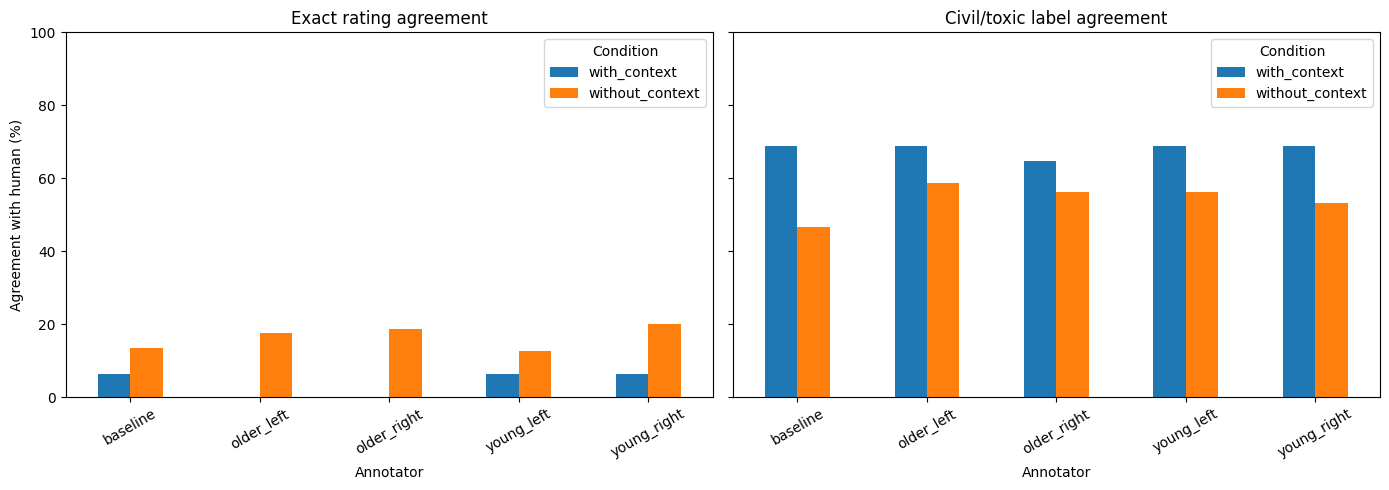

In [157]:
import matplotlib.pyplot as plt

# Arrange the human-model agreement results for plotting
plot_data = human_comparison.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

metrics = [
    ("exact_rating_agreement", "Exact rating agreement"),
    ("label_agreement", "Civil/toxic label agreement")
]

for ax, (metric, title) in zip(axes, metrics):
    values = plot_data.pivot(
        index="annotator",
        columns="condition",
        values=metric
    )

    values.plot.bar(ax=ax, rot=30)
    ax.set_title(title)
    ax.set_xlabel("Annotator")
    ax.set_ylabel("Agreement with human (%)")
    ax.set_ylim(0, 100)
    ax.legend(title="Condition")

plt.tight_layout()
plt.show()

The sample in this study contains 20 comments, so the results might not be representative of other comments. It is therefore important to understand that we cannot generalize these findings beyond this sample. Additionally, 40 answers were excluded from the comparisons because their evidence was not found exactly in the original comments during validation.

The personas were simulated using the same language model, Qwen 2.5, so they do not represent any real-life groups. The observed differences associated with age, politics, or context come from this model responding under different personas and conditions.

## AI use and sources
I used ChatGPT to help me understand the structure of the lab-1 and the assignment, the different libraries that have been used during the labs in order to construct the code above. I used them also for debugging in many occasions, removing of duplicates and to save the comments, texts, ratings and annotations locally. The comments on the graphs are genuinely mine, I challenged ChatGPT find problems with my interpretations.
